In [41]:
import pandas as pd

df = pd.read_csv("maharashtra_telecom_synthetic_50000.csv")

print(df.head())
print(df.shape)
print(df.columns)
print(df.info())
print(df.isnull().sum())

         date        state   district operator network  download_speed_mbps  \
0  2026-09-14  Maharashtra     Nashik     BSNL      5G                69.20   
1  2026-08-18  Maharashtra   Bhandara     BSNL      4G                34.06   
2  2026-11-09  Maharashtra  Osmanabad       Vi      5G                77.12   
3  2026-09-04  Maharashtra   Amravati   Airtel      5G               205.86   
4  2026-05-18  Maharashtra   Amravati   Airtel      5G               244.72   

   upload_speed_mbps  ping_ms  signal_dbm  call_drops  complaints  \
0              15.61     28.5       -85.1           0           0   
1              11.59     40.7       -92.7           0           0   
2              22.21     22.3       -87.4           0           0   
3              49.22     26.4       -88.0           0           1   
4              64.67     44.8       -85.3           0           0   

      issue_type        status  
0  Slow Internet       Pending  
1  Slow Internet      Resolved  
2       No 

In [5]:
print(df.head())
print(df.info())

   serial_no                   service_provider service_area_code  \
0          2   Aerpace Communications Pvt. Ltd.                MH   
1          3   Aerpace Communications Pvt. Ltd.               MUM   
2          6  Airnet Cable and Datacom Pvt.Ltd.                MH   
3          7  Airnet Cable and Datacom Pvt.Ltd.               MUM   
4          8     Alegra Communication Pvt. Ltd.                MH   

   service_provisioning_pct  latency_ms  packet_drop_rate_pct  \
0                     100.0       10.00                  0.20   
1                     100.0       10.00                  0.00   
2                     100.0        1.03                  0.03   
3                     100.0        1.16                  0.10   
4                       NaN       48.00                  0.65   

   maximum_bandwidth_utilization_pct  jitter_ms  \
0                               30.0      20.00   
1                               30.0      20.00   
2                               43.7     

In [42]:
# Dataset size
print("Shape:", df.shape)

# Column names
print("\nColumns:")
print(df.columns)

# Dataset information
print("\nInformation:")
df.info()

# Statistical summary
print("\nStatistics:")
print(df.describe())

Shape: (50000, 13)

Columns:
Index(['date', 'state', 'district', 'operator', 'network',
       'download_speed_mbps', 'upload_speed_mbps', 'ping_ms', 'signal_dbm',
       'call_drops', 'complaints', 'issue_type', 'status'],
      dtype='str')

Information:
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   date                 50000 non-null  str    
 1   state                50000 non-null  str    
 2   district             50000 non-null  str    
 3   operator             50000 non-null  str    
 4   network              50000 non-null  str    
 5   download_speed_mbps  50000 non-null  float64
 6   upload_speed_mbps    50000 non-null  float64
 7   ping_ms              50000 non-null  float64
 8   signal_dbm           50000 non-null  float64
 9   call_drops           50000 non-null  int64  
 10  complaints           50000 non-null  int

In [47]:
for col in df.columns:
    print(col)

date
state
district
operator
network
download_speed_mbps
upload_speed_mbps
ping_ms
signal_dbm
call_drops
complaints
issue_type
status


# data cleaning

In [43]:
#Check missing values
df.isna().sum()

date                   0
state                  0
district               0
operator               0
network                0
download_speed_mbps    0
upload_speed_mbps      0
ping_ms                0
signal_dbm             0
call_drops             0
complaints             0
issue_type             0
status                 0
dtype: int64

In [14]:
#check duplicates 
df.duplicated().sum()

np.int64(0)

In [45]:
print("Original Missing:", df.isnull().sum().sum())

print("Mean Missing:", df_mean.isnull().sum().sum())

print("Median Missing:", df_median.isnull().sum().sum())

Original Missing: 0
Mean Missing: 0
Median Missing: 0


In [48]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


# Exploratory Data Analysis (EDA)

In [21]:
#Dataset summary
print(df.head())
print(df.shape)
print(df.describe())

   serial_no                   service_provider service_area_code  \
0          2   Aerpace Communications Pvt. Ltd.                MH   
1          3   Aerpace Communications Pvt. Ltd.               MUM   
2          6  Airnet Cable and Datacom Pvt.Ltd.                MH   
3          7  Airnet Cable and Datacom Pvt.Ltd.               MUM   
4          8     Alegra Communication Pvt. Ltd.                MH   

   service_provisioning_pct  latency_ms  packet_drop_rate_pct  \
0                     100.0       10.00                  0.20   
1                     100.0       10.00                  0.00   
2                     100.0        1.03                  0.03   
3                     100.0        1.16                  0.10   
4                       NaN       48.00                  0.65   

   maximum_bandwidth_utilization_pct  jitter_ms  \
0                               30.0      20.00   
1                               30.0      20.00   
2                               43.7     

In [49]:
#Standardize Text Columns
#Standardize Text Columns
# Select text columns
text_cols = df.select_dtypes(include="object").columns

# Remove extra spaces
for col in text_cols:
    df[col] = df[col].str.strip()

# Convert text to consistent format
df["operator"] = df["operator"].str.title()
df["district"] = df["district"].str.title()
df["network"] = df["network"].str.upper()
df["issue_type"] = df["issue_type"].str.title()
df["status"] = df["status"].str.title()

print("Text cleaning completed!")

Text cleaning completed!


C:\Users\Win 10\AppData\Local\Temp\ipykernel_3284\1077718916.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_cols = df.select_dtypes(include="object").columns


In [50]:
# Convert Date Column
# Convert date column to datetime
df["date"] = pd.to_datetime(df["date"], errors="coerce")

# Check data type
print(df["date"].dtype)

# Display sample dates
print(df["date"].head())

datetime64[us]
0   2026-09-14
1   2026-08-18
2   2026-11-09
3   2026-09-04
4   2026-05-18
Name: date, dtype: datetime64[us]


In [51]:
# check outliers 
# Select numerical columns
num_cols = df.select_dtypes(include="number").columns

# Calculate outliers using IQR
outlier_result = []

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = ((df[col] < lower) | (df[col] > upper)).sum()

    outlier_result.append({
        "Column": col,
        "Lower Limit": round(lower, 2),
        "Upper Limit": round(upper, 2),
        "Outliers": outliers
    })

outlier_df = pd.DataFrame(outlier_result)

outlier_df

,Column,Lower Limit,Upper Limit,Outliers
0,download_speed_mbps,-89.53,211.97,3508
1,upload_speed_mbps,-20.68,48.96,4543
2,ping_ms,-7.30,88.70,36
3,signal_dbm,-112.60,-53.40,342
4,call_drops,-1.50,2.50,1320
5,complaints,0.00,0.00,11637


# — Exploratory Data Analysis (EDA).

In [52]:
#Descriptive Statistics
print(df.describe())

                             date  download_speed_mbps  upload_speed_mbps  \
count                       50000         50000.000000        50000.00000   
mean   2026-06-07 18:52:37.055999            73.683667           18.40746   
min           2026-01-01 00:00:00             2.680000            0.64000   
25%           2026-03-20 00:00:00            23.530000            5.43000   
50%           2026-06-08 00:00:00            38.315000            9.59000   
75%           2026-08-26 00:00:00            98.905000           22.84000   
max           2026-11-13 00:00:00           650.000000          180.00000   
std                           NaN            79.761575           21.47606   

            ping_ms    signal_dbm    call_drops    complaints  
count  50000.000000  50000.000000  50000.000000  50000.000000  
mean      40.499488    -83.014490      0.528140      0.275060  
min        5.000000   -120.000000      0.000000      0.000000  
25%       28.700000    -90.400000      0.000000   

In [54]:
#Calculate Business KPIs

total_records = len(df)

avg_download = df["download_speed_mbps"].mean()
avg_upload = df["upload_speed_mbps"].mean()
avg_ping = df["ping_ms"].mean()
avg_signal = df["signal_dbm"].mean()

total_call_drops = df["call_drops"].sum()
total_complaints = df["complaints"].sum()

print("Total Records:", total_records)
print("Average Download Speed:", round(avg_download, 2), "Mbps")
print("Average Upload Speed:", round(avg_upload, 2), "Mbps")
print("Average Ping:", round(avg_ping, 2), "ms")
print("Average Signal:", round(avg_signal, 2), "dBm")
print("Total Call Drops:", total_call_drops)
print("Total Complaints:", total_complaints)

Total Records: 50000
Average Download Speed: 73.68 Mbps
Average Upload Speed: 18.41 Mbps
Average Ping: 40.5 ms
Average Signal: -83.01 dBm
Total Call Drops: 26407
Total Complaints: 13753


# Visualize upload speed

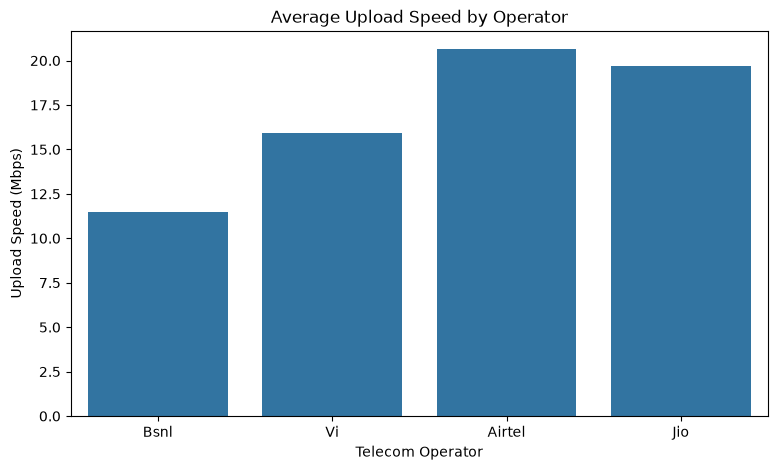

In [56]:
# Visualize upload speed
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="operator",
    y="upload_speed_mbps",
    estimator="mean",
    errorbar=None
)

plt.title("Average Upload Speed by Operator")
plt.xlabel("Telecom Operator")
plt.ylabel("Upload Speed (Mbps)")
plt.show()

# Find 10 districts with the lowest speed

In [58]:
# Find 10 districts with the lowest speed
district = df.groupby("district")["download_speed_mbps"].mean()

worst_10 = district.sort_values().head(10)

print(worst_10)

district
Akola         68.117478
Nagpur        68.807522
Mumbai        70.247854
Chandrapur    70.368358
Bhandara      70.483876
Nandurbar     71.379575
Aurangabad    71.649873
Palghar       71.832495
Nanded        72.336796
Raigad        72.452772
Name: download_speed_mbps, dtype: float64


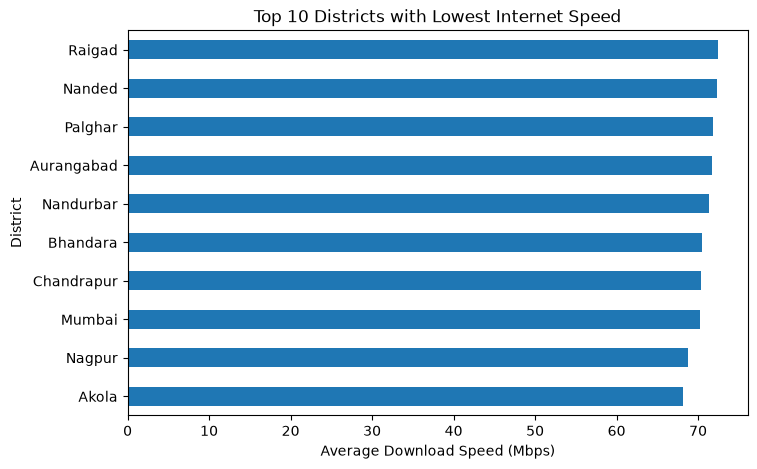

In [59]:
plt.figure(figsize=(8, 5))

worst_10.plot(kind="barh")

plt.title("Top 10 Districts with Lowest Internet Speed")
plt.xlabel("Average Download Speed (Mbps)")
plt.ylabel("District")

plt.show()

# Which Telecom Operator Receives the Most Complaints?

In [60]:
# Which Telecom Operator Receives the Most Complaints?
complaints = df.groupby("operator")["complaints"].sum()

complaints = complaints.sort_values(ascending=False)

print(complaints)

operator
Jio       5040
Airtel    4412
Vi        2800
Bsnl      1501
Name: complaints, dtype: int64


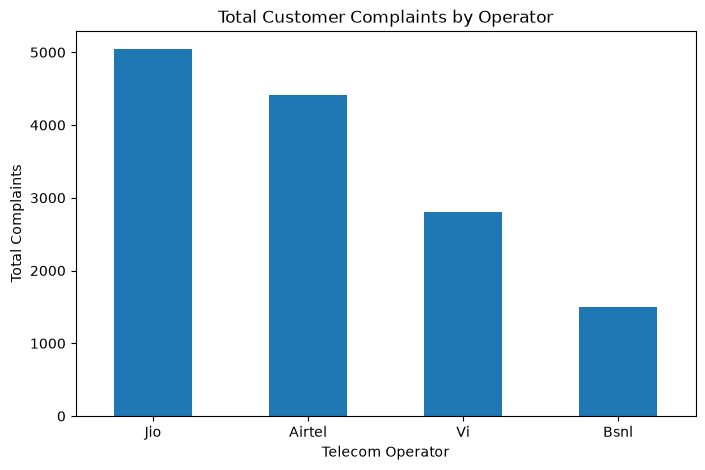

In [61]:
plt.figure(figsize=(8, 5))

complaints.plot(kind="bar")

plt.title("Total Customer Complaints by Operator")
plt.xlabel("Telecom Operator")
plt.ylabel("Total Complaints")
plt.xticks(rotation=0)

plt.show()

# 5G Faster Than 4G?

In [63]:
network_speed = df.groupby("network")["download_speed_mbps"].mean()

print(network_speed)

network
4G     31.773630
5G    163.078965
Name: download_speed_mbps, dtype: float64


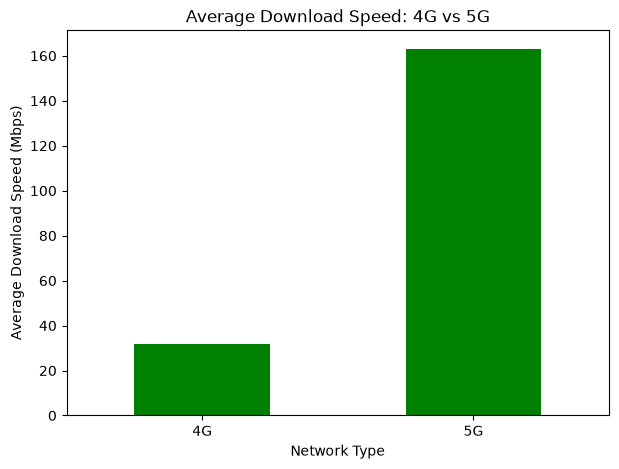

In [68]:
network_speed.plot(kind="bar", figsize=(7, 5),color="green")

plt.title("Average Download Speed: 4G vs 5G")
plt.xlabel("Network Type")
plt.ylabel("Average Download Speed (Mbps)")
plt.xticks(rotation=0)
plt.show()

# What Is the Most Common Network Issue?

In [65]:
# Remove records with no network issue
issue_data = df[df["issue_type"] != "No Issue"]

# Count each issue
issue_count = issue_data["issue_type"].value_counts()

print(issue_count)

issue_type
Slow Internet    4561
Weak Signal      4116
Call Drop        3482
High Ping        2987
No Network       1523
Name: count, dtype: int64


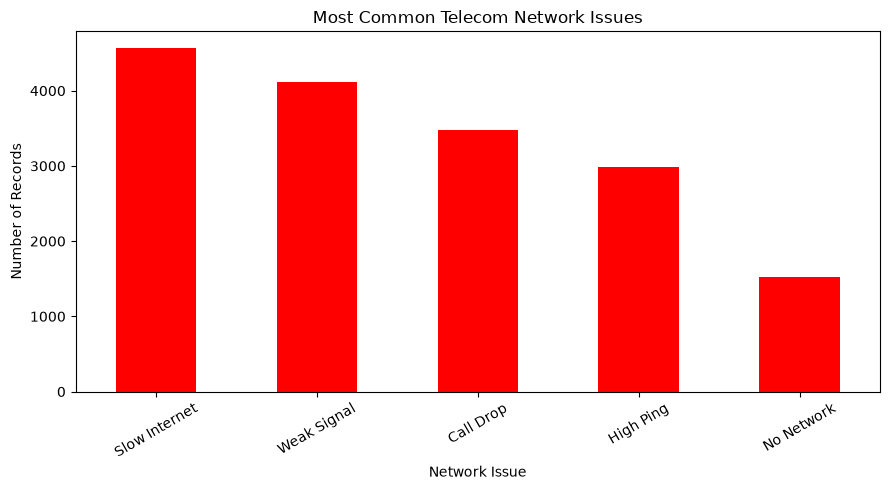

In [67]:
plt.figure(figsize=(9, 5))

issue_count.plot(kind="bar",color="red")

plt.title("Most Common Telecom Network Issues")
plt.xlabel("Network Issue")
plt.ylabel("Number of Records")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

# Which Operator Has the Best Complaint Resolution Rate?

In [69]:
# Remove records without complaints
complaint_df = df[df["status"] != "No Complaint"]

# Calculate operator-wise resolution percentage
resolution = pd.crosstab(
    complaint_df["operator"],
    complaint_df["status"],
    normalize="index"
) * 100

resolution = resolution.round(2)

print(resolution)

status    Pending  Resolved
operator                   
Airtel      22.06     77.94
Bsnl        21.73     78.27
Jio         21.89     78.11
Vi          21.33     78.67


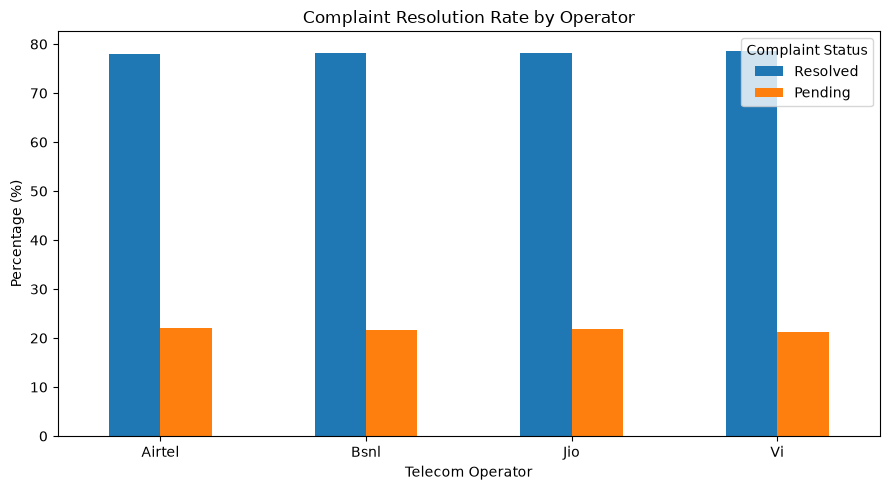

In [70]:
resolution[["Resolved", "Pending"]].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Complaint Resolution Rate by Operator")
plt.xlabel("Telecom Operator")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Complaint Status")
plt.tight_layout()
plt.show()

# Does High Ping Affect Internet Speed?

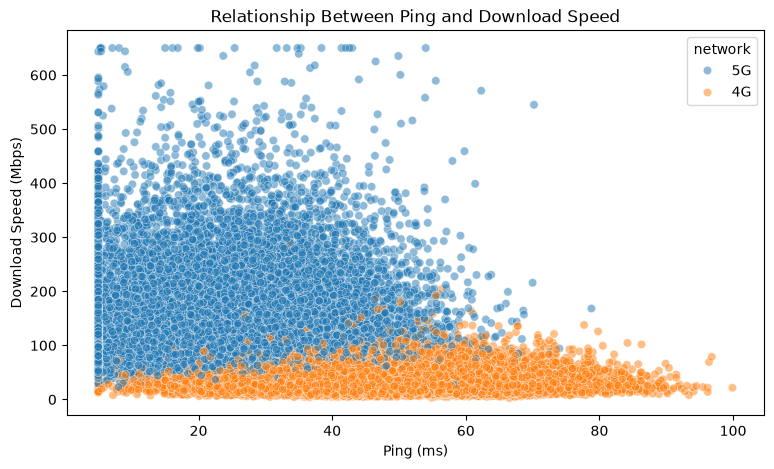

In [71]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="ping_ms",
    y="download_speed_mbps",
    hue="network",
    alpha=0.5
)

plt.title("Relationship Between Ping and Download Speed")
plt.xlabel("Ping (ms)")
plt.ylabel("Download Speed (Mbps)")
plt.show()

# Which Telecom Operator Has More Call Drops?

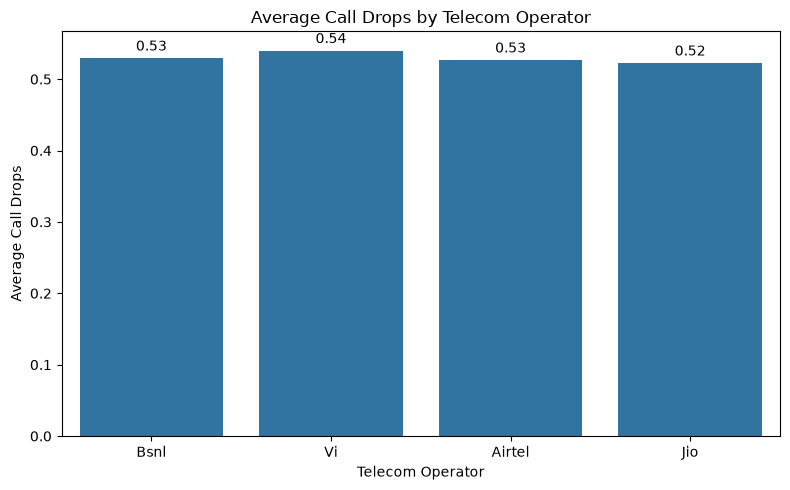

In [73]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=df,
    x="operator",
    y="call_drops",
    estimator="mean",
    errorbar=None
)

# Add values on bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

plt.title("Average Call Drops by Telecom Operator")
plt.xlabel("Telecom Operator")
plt.ylabel("Average Call Drops")

plt.tight_layout()
plt.show()

# Which District Has the Most Customer Complaints?

In [74]:
district_complaints = (
    df.groupby("district")["complaints"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

print(district_complaints)

          district  complaints
0           Washim         430
1           Nagpur         427
2           Mumbai         426
3        Ratnagiri         422
4            Thane         420
5  Mumbai Suburban         412
6           Gondia         410
7          Jalgaon         407
8       Sindhudurg         405
9        Nandurbar         404


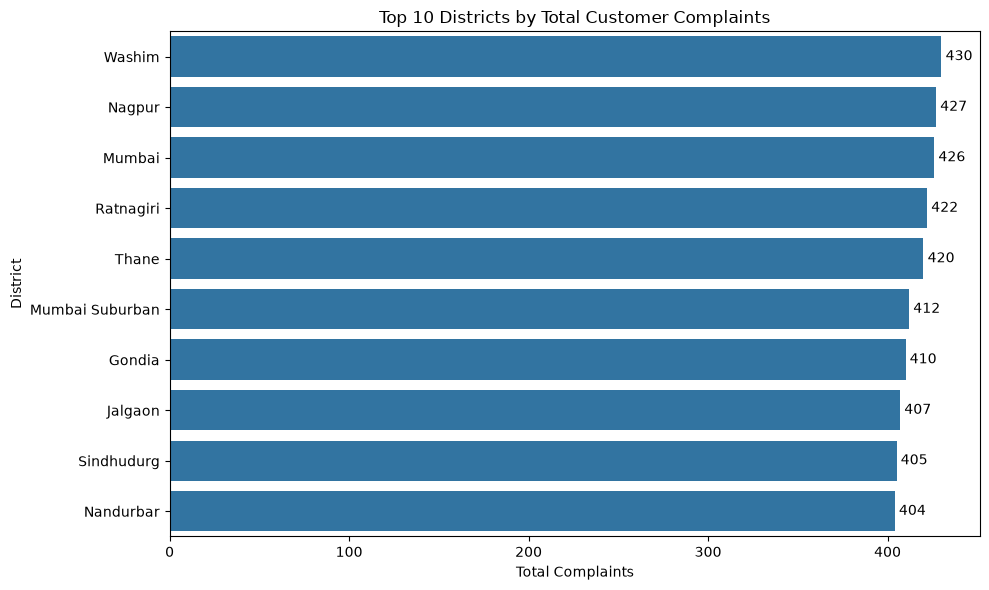

In [75]:
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=district_complaints,
    x="complaints",
    y="district"
)

# Display values on bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.title("Top 10 Districts by Total Customer Complaints")
plt.xlabel("Total Complaints")
plt.ylabel("District")

plt.tight_layout()
plt.show()

# Which Operator Performs Better in 4G and 5G?

In [76]:
speed_data = df.pivot_table(
    index="operator",
    columns="network",
    values="download_speed_mbps",
    aggfunc="mean"
)

speed_data.round(2)

network,4G,5G
operator,,
Airtel,35.28,183.79
Bsnl,19.48,100.35
Jio,34.20,174.04
Vi,27.63,141.99


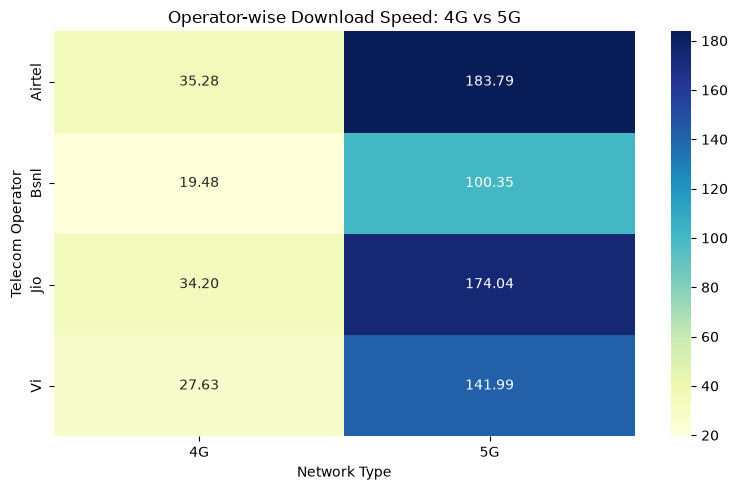

In [77]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    speed_data,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu"
)

plt.title("Operator-wise Download Speed: 4G vs 5G")
plt.xlabel("Network Type")
plt.ylabel("Telecom Operator")

plt.tight_layout()
plt.show()

# does Weak Network Signal Increase Call Drops?

In [79]:
df["signal_group"] = pd.qcut(
    df["signal_dbm"],
    q=3,
    labels=["Weak Signal", "Medium Signal", "Strong Signal"]
)

In [80]:
signal_analysis = df.groupby(
    "signal_group",
    observed=True
)["call_drops"].mean().reset_index()

print(signal_analysis)

    signal_group  call_drops
0    Weak Signal    0.689505
1  Medium Signal    0.450668
2  Strong Signal    0.443598


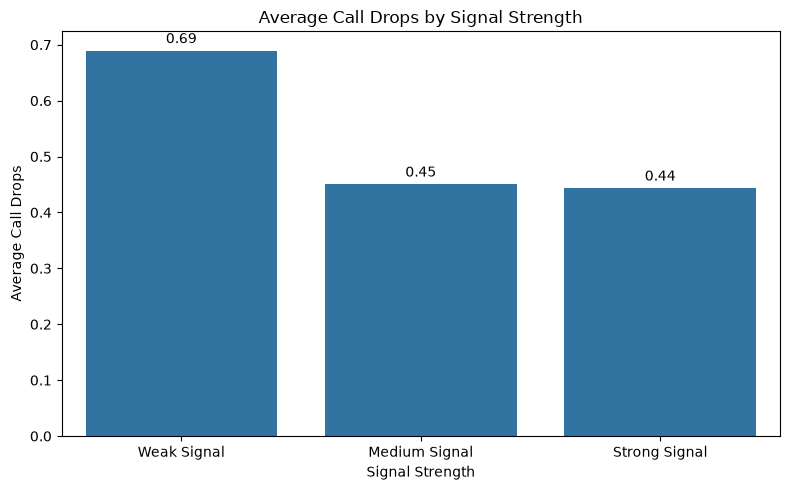

In [81]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=signal_analysis,
    x="signal_group",
    y="call_drops",
    errorbar=None
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

plt.title("Average Call Drops by Signal Strength")
plt.xlabel("Signal Strength")
plt.ylabel("Average Call Drops")

plt.tight_layout()
plt.show()

# How Do Customer Complaints Change Month by Month?

In [82]:
monthly_complaints = (
    df.groupby(df["date"].dt.month)["complaints"]
    .mean()
    .reset_index()
)

monthly_complaints.columns = ["month", "avg_complaints"]

print(monthly_complaints)

    month  avg_complaints
0       1        0.276413
1       2        0.265246
2       3        0.284876
3       4        0.273867
4       5        0.274093
5       6        0.276551
6       7        0.273795
7       8        0.277535
8       9        0.279202
9      10        0.272290
10     11        0.266003


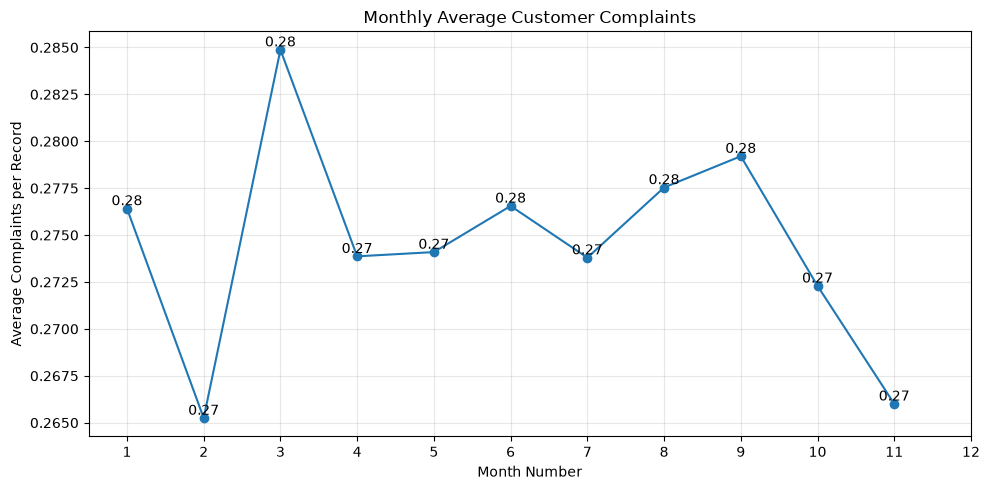

In [83]:
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_complaints["month"],
    monthly_complaints["avg_complaints"],
    marker="o"
)

# Show values on graph
for x, y in zip(
    monthly_complaints["month"],
    monthly_complaints["avg_complaints"]
):
    plt.text(x, y, round(y, 2), ha="center", va="bottom")

plt.title("Monthly Average Customer Complaints")
plt.xlabel("Month Number")
plt.ylabel("Average Complaints per Record")
plt.xticks(range(1, 13))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# How Is Internet Download Speed Distributed?

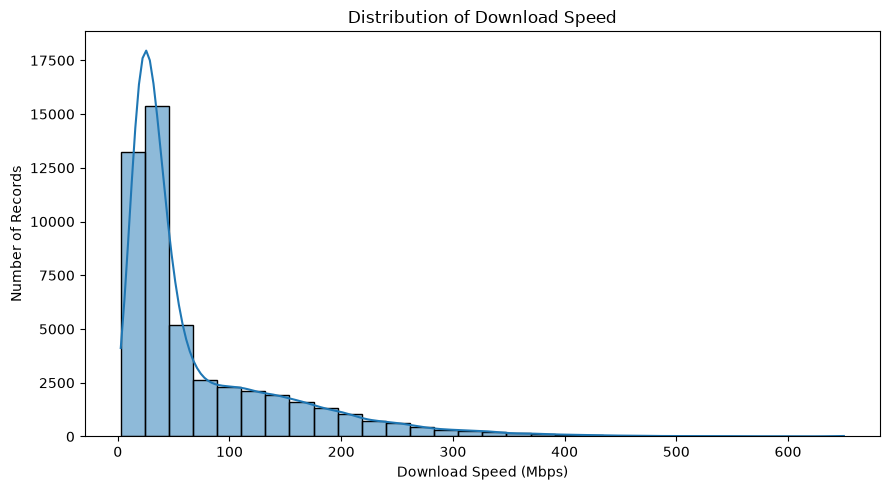

In [84]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="download_speed_mbps",
    bins=30,
    kde=True
)

plt.title("Distribution of Download Speed")
plt.xlabel("Download Speed (Mbps)")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.show()

# Correlation Between Telecom Network Metrics

In [85]:
corr = df[
    [
        "download_speed_mbps",
        "upload_speed_mbps",
        "ping_ms",
        "signal_dbm",
        "call_drops",
        "complaints"
    ]
].corr()

corr.round(2)

,download_speed_mbps,upload_speed_mbps,ping_ms,signal_dbm,call_drops,complaints
download_speed_mbps,1.00,0.93,-0.50,-0.00,0.01,-0.00
upload_speed_mbps,0.93,1.00,-0.47,-0.01,0.01,-0.00
ping_ms,-0.50,-0.47,1.00,0.00,-0.01,0.01
signal_dbm,-0.00,-0.01,0.00,1.00,-0.20,-0.09
call_drops,0.01,0.01,-0.01,-0.20,1.00,0.06
complaints,-0.00,-0.00,0.01,-0.09,0.06,1.00


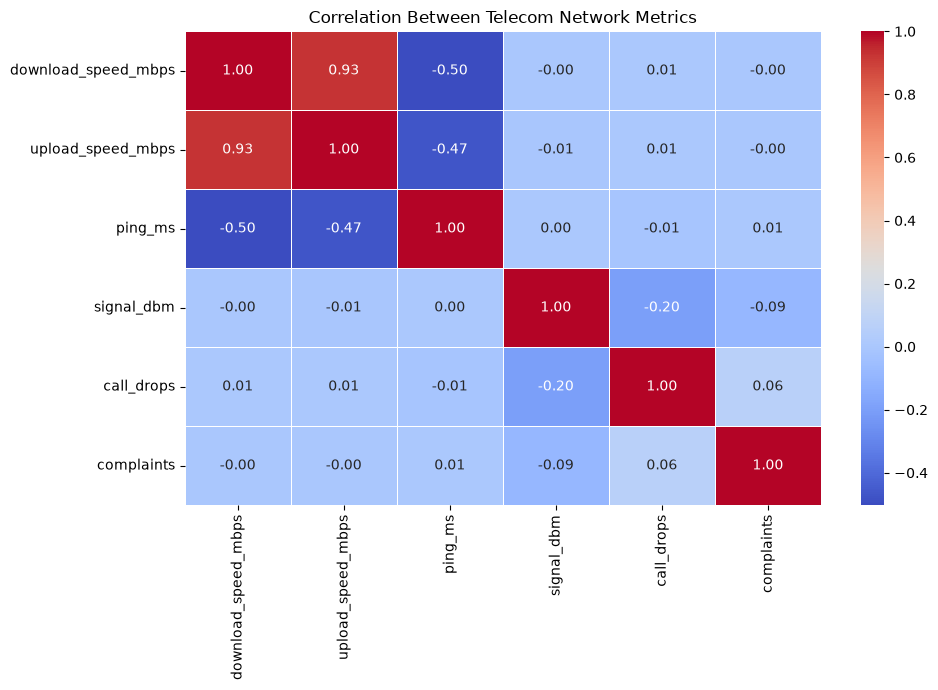

In [86]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Telecom Network Metrics")
plt.tight_layout()
plt.show()

# Generate key business findings

In [87]:
# 1. Operator performance
operator_speed = df.groupby("operator")["download_speed_mbps"].mean()

# 2. District performance
district_speed = df.groupby("district")["download_speed_mbps"].mean()

# 3. Operator complaints
operator_complaints = df.groupby("operator")["complaints"].mean()

# 4. Network comparison
network_speed = df.groupby("network")["download_speed_mbps"].mean()

# 5. Most common network issue
issue_count = df[df["issue_type"] != "No Issue"]["issue_type"].value_counts()

print("HIGHEST DOWNLOAD SPEED:", operator_speed.idxmax())
print("LOWEST DOWNLOAD SPEED:", operator_speed.idxmin())

print("\nLOWEST PERFORMING DISTRICT:", district_speed.idxmin())

print("\nHIGHEST AVERAGE COMPLAINTS:", operator_complaints.idxmax())

print("\nFASTER NETWORK:", network_speed.idxmax())

print("\nMOST COMMON NETWORK ISSUE:", issue_count.idxmax())

HIGHEST DOWNLOAD SPEED: Airtel
LOWEST DOWNLOAD SPEED: Bsnl

LOWEST PERFORMING DISTRICT: Akola

HIGHEST AVERAGE COMPLAINTS: Bsnl

FASTER NETWORK: 5G

MOST COMMON NETWORK ISSUE: Slow Internet


# Business Insights and Recommendations

## Business Insights

1. Operator Performance: Identified operators with the highest and lowest average download speeds.
2. District Performance: Identified districts with comparatively lower internet speeds.
3. Customer Complaints: Analyzed complaint patterns across telecom operators.
4. Network Comparison: Compared average download speeds between 4G and 5G.
5. Network Issues: Identified the most frequently recorded network issue.
6. Signal Quality: Examined the relationship between signal strength and call drops.

## Business Recommendations

1. Investigate districts with lower average download speeds.
2. Analyze the reasons for higher customer complaints.
3. Improve network coverage in weak-signal areas.
4. Investigate network conditions associated with higher call drops.
5. Monitor network performance regularly.
6. Improve complaint resolution processes.

## EDA Conclusion

Exploratory Data Analysis helped identify patterns in telecom network performance, district-level differences, customer complaints and network issues. These findings can support better business decisions and network improvement planning.

In [88]:
df.to_csv("maharashtra_telecom_cleaned.csv", index=False)